# MME Perception Scores


In [7]:
from pathlib import Path
import sys
import json
import os
import matplotlib.pyplot as plt

MME_DIR = Path.cwd()
sys.path.append(str(MME_DIR))


In [8]:
results_path = results_file = next((f for f in os.listdir(MME_DIR) if 'results' in f), None)
if results_path:
    with open(MME_DIR / results_path, 'r') as f:
        perception_scores = [json.loads(line) for line in f]
else:
    perception_scores = None

In [9]:
# check the experiment names in perception_scores
# split the experiment names by '/' and take the first part
# if the split experiment name do not have finetuned in it then print it
# store just the unique experiment names
models_collection = set()
for score in perception_scores:
    exp_name = score['experiment_name'].split('/')[0]
    if 'finetuned' not in exp_name:
        models_collection.add(exp_name)

data = { exp: {} for exp in models_collection }
checkpoint_steps = [str(i) for i in range(1000, 10001, 1000)]
for collection in models_collection:
    for experiment in perception_scores:
        exp_name = experiment['experiment_name'].split('/')[0]
        # Exact match on the collection name (before the '/')
        if exp_name == collection:
            step = experiment['experiment_name'].split('-')[-1]
            if step in checkpoint_steps:
                data[collection][int(step)] = experiment['perception']['total_score']/2000

# Find experiment ending with 'finetuned'
finetuned_exp = next((exp for exp in perception_scores if exp['experiment_name'].endswith('finetuned')), None)

# Find experiment ending with 'pretrained'
pretrained_exp = next((exp for exp in perception_scores if exp['experiment_name'].endswith('pretrained')), None)
if finetuned_exp:
    data['finetuned'] = finetuned_exp['perception']['total_score']/2000
if pretrained_exp:
    data['pretrained'] = pretrained_exp['perception']['total_score']/2000
data

{'Llava1.5-7B-frozen': {10000: 0.5348213285314125,
  1000: 0.5860832332933174,
  2000: 0.5668801520608243,
  3000: 0.5718738495398159,
  4000: 0.549796918767507,
  5000: 0.5640755302120849,
  6000: 0.5646744197679072,
  7000: 0.5461780212084835,
  8000: 0.537546068427371,
  9000: 0.5394769407763106},
 'Llava1.5-7B-18-32': {10000: 0.6090598239295718,
  1000: 0.4677284413765506,
  2000: 0.5843904561824729,
  3000: 0.6685393157262906,
  4000: 0.5903585934373751,
  5000: 0.619891756702681,
  6000: 0.6813325830332133,
  7000: 0.623000150060024,
  8000: 0.5892239395758304,
  9000: 0.5925123549419768},
 'Llava1.5-7B-2-2': {10000: 0.5851075430172068,
  1000: 0.5884282713085234,
  2000: 0.5510453681472588,
  3000: 0.5554915466186475,
  4000: 0.5804673369347738,
  5000: 0.582624599839936,
  6000: 0.5770640256102441,
  7000: 0.5886680172068828,
  8000: 0.5831398059223689,
  9000: 0.5805193077230892},
 'Llava1.5-7B-2-18': {10000: 0.7108862545018008,
  1000: 0.6570711284513806,
  2000: 0.6981859243

In [10]:
models_collection

{'Llava1.5-7B',
 'Llava1.5-7B-18-32',
 'Llava1.5-7B-2-18',
 'Llava1.5-7B-2-2',
 'Llava1.5-7B-frozen'}

In [23]:
0.7364654861944777 * 2000

1472.9309723889555

In [11]:
basename = "Llava1.5-7B"
NAMES_MAPPING = {
    basename: "full",
    f"{basename}-2-18": "2-18",
    f"{basename}-18-32": "18-32",
    f"{basename}-2-2": "2-2",
    f"{basename}-frozen": "frozen_llm",
    "finetuned": "FM",
    "pretrained": "PM"
}

COLOR_SCHEME = {
    'full': '#08519c',      # Dark blue - all layers fine-tuned
    '2-18': '#6baed6',      # Medium blue - early-upper layers
    '18-32': '#9ecae1',     # Light blue - upper layers only
    '2-2': '#c6dbef',     # Very light blue - middle layers (reserved)
    'frozen_llm': '#006d2c',   # Dark green - frozen projector, all LLM layers trained
    'PM': 'black',
    'FM': 'red',
}

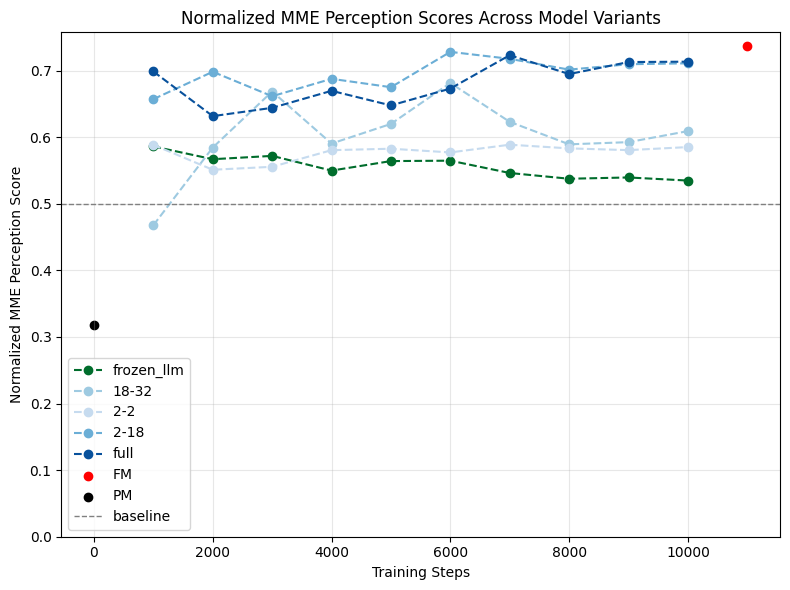

In [21]:
fig, ax = plt.subplots(figsize=(8, 6))
for collection in models_collection:
    label = NAMES_MAPPING.get(collection, collection)
    color = COLOR_SCHEME.get(label, "#000000")
    if data[collection]:  # Only plot if there's data
        steps, scores = zip(*sorted(data[collection].items()))
        ax.plot(
            steps,
            scores,
            label=label,
            color=color,
            marker="o",
            linestyle="--",
        )

if "finetuned" in data:
    label = NAMES_MAPPING.get("finetuned", "finetuned")
    color = COLOR_SCHEME.get(label, "red")
    ax.scatter(11000, data["finetuned"], label=label, color=color, marker="o")

if "pretrained" in data:
    label = NAMES_MAPPING.get("pretrained", "pretrained")
    color = COLOR_SCHEME.get(label, "green")
    ax.scatter(0, data["pretrained"], label=label, color=color, marker="o")

ax.axhline(y=0.5, color='gray', linestyle='--', linewidth=1, label='baseline')

ax.set_ylim(ymin=0)

ax.set_xlabel("Training Steps")
ax.set_ylabel("Normalized MME Perception Score")
ax.set_title("Normalized MME Perception Scores Across Model Variants")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
cognition_data = { exp: {} for exp in models_collection }
checkpoint_steps = [str(i) for i in range(1000, 10001, 1000)]
for collection in models_collection:
    for experiment in perception_scores:
        exp_name = experiment['experiment_name'].split('/')[0]
        # Exact match on the collection name (before the '/')
        if exp_name == collection:
            step = experiment['experiment_name'].split('-')[-1]
            if step in checkpoint_steps:
                cognition_data[collection][int(step)] = experiment['cognition']['total_score']/800

# Find experiment ending with 'finetuned'
finetuned_exp = next((exp for exp in perception_scores if exp['experiment_name'].endswith('finetuned')), None)

# Find experiment ending with 'pretrained'
pretrained_exp = next((exp for exp in perception_scores if exp['experiment_name'].endswith('pretrained')), None)
if finetuned_exp:
    cognition_data['finetuned'] = finetuned_exp['cognition']['total_score']/800
if pretrained_exp:
    cognition_data['pretrained'] = pretrained_exp['cognition']['total_score']/800
cognition_data

{'Llava1.5-7B-frozen': {10000: 0.12464285714285714,
  1000: 0.1355357142857143,
  2000: 0.13071428571428573,
  3000: 0.13785714285714287,
  4000: 0.12928571428571428,
  5000: 0.13017857142857145,
  6000: 0.13,
  7000: 0.12892857142857145,
  8000: 0.1275,
  9000: 0.12589285714285714},
 'Llava1.5-7B-18-32': {10000: 0.17303571428571426,
  1000: 0.11446428571428571,
  2000: 0.15964285714285714,
  3000: 0.13,
  4000: 0.16089285714285714,
  5000: 0.1525,
  6000: 0.12821428571428573,
  7000: 0.16982142857142857,
  8000: 0.16017857142857145,
  9000: 0.15214285714285714},
 'Llava1.5-7B-2-2': {10000: 0.1475,
  1000: 0.13196428571428573,
  2000: 0.14642857142857144,
  3000: 0.14714285714285713,
  4000: 0.13607142857142857,
  5000: 0.14428571428571427,
  6000: 0.1525,
  7000: 0.1457142857142857,
  8000: 0.14160714285714285,
  9000: 0.1425},
 'Llava1.5-7B-2-18': {10000: 0.16464285714285715,
  1000: 0.13214285714285715,
  2000: 0.13232142857142856,
  3000: 0.14392857142857143,
  4000: 0.167678571428

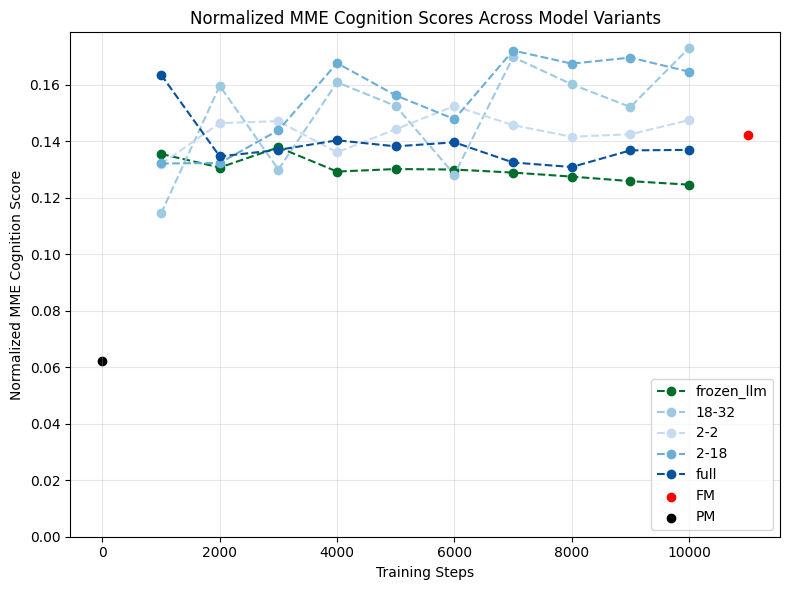

In [20]:
fig, ax = plt.subplots(figsize=(8, 6))
for collection in models_collection:
    label = NAMES_MAPPING.get(collection, collection)
    color = COLOR_SCHEME.get(label, "#000000")
    if cognition_data[collection]:  # Only plot if there's data
        steps, scores = zip(*sorted(cognition_data[collection].items()))
        ax.plot(
            steps,
            scores,
            label=label,
            color=color,
            marker="o",
            linestyle="--",
        )

if "finetuned" in data:
    label = NAMES_MAPPING.get("finetuned", "finetuned")
    color = COLOR_SCHEME.get(label, "red")
    ax.scatter(11000, cognition_data["finetuned"], label=label, color=color, marker="o")

if "pretrained" in data:
    label = NAMES_MAPPING.get("pretrained", "pretrained")
    color = COLOR_SCHEME.get(label, "green")
    ax.scatter(0, cognition_data["pretrained"], label=label, color=color, marker="o")

# ax.axhline(y=0.25, color='gray', linestyle='-', linewidth=1, label='baseline')

ax.set_ylim(ymin=0)

ax.set_xlabel("Training Steps")
ax.set_ylabel("Normalized MME Cognition Score")
ax.set_title("Normalized MME Cognition Scores Across Model Variants")
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

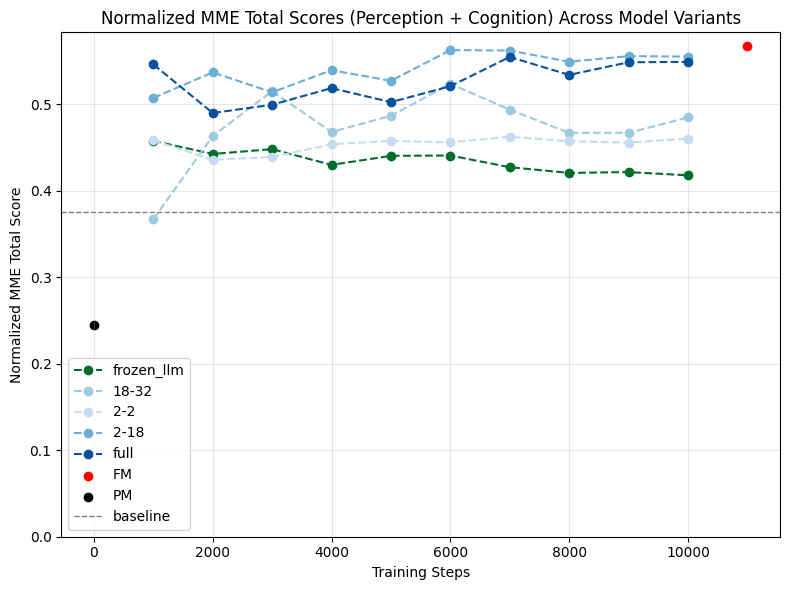

In [22]:
# Calculate total scores: denormalize, sum, then normalize by 2800
total_data = {exp: {} for exp in models_collection}
checkpoint_steps = [str(i) for i in range(1000, 10001, 1000)]
for collection in models_collection:
    for experiment in perception_scores:
        exp_name = experiment['experiment_name'].split('/')[0]
        if exp_name == collection:
            step = experiment['experiment_name'].split('-')[-1]
            if step in checkpoint_steps:
                perception_actual = data[collection][int(step)] * 2000
                cognition_actual = cognition_data[collection][int(step)] * 800
                total_actual = perception_actual + cognition_actual
                total_data[collection][int(step)] = total_actual / 2800

# Handle finetuned and pretrained
if finetuned_exp:
    perception_actual = data['finetuned'] * 2000
    cognition_actual = cognition_data['finetuned'] * 800
    total_actual = perception_actual + cognition_actual
    total_data['finetuned'] = total_actual / 2800

if pretrained_exp:
    perception_actual = data['pretrained'] * 2000
    cognition_actual = cognition_data['pretrained'] * 800
    total_actual = perception_actual + cognition_actual
    total_data['pretrained'] = total_actual / 2800

# Plot the total normalized scores
fig, ax = plt.subplots(figsize=(8, 6))
for collection in models_collection:
    label = NAMES_MAPPING.get(collection, collection)
    color = COLOR_SCHEME.get(label, "#000000")
    if total_data[collection]:
        steps, scores = zip(*sorted(total_data[collection].items()))
        ax.plot(
            steps,
            scores,
            label=label,
            color=color,
            marker="o",
            linestyle="--",
        )

if "finetuned" in total_data:
    label = NAMES_MAPPING.get("finetuned", "finetuned")
    color = COLOR_SCHEME.get(label, "red")
    ax.scatter(11000, total_data["finetuned"], label=label, color=color, marker="o")

if "pretrained" in total_data:
    label = NAMES_MAPPING.get("pretrained", "pretrained")
    color = COLOR_SCHEME.get(label, "green")
    ax.scatter(0, total_data["pretrained"], label=label, color=color, marker="o")

ax.axhline(y=0.375, color='gray', linestyle='--', linewidth=1, label='baseline')

ax.set_ylim(ymin=0)

ax.set_xlabel("Training Steps")
ax.set_ylabel("Normalized MME Total Score")
ax.set_title("Normalized MME Total Scores (Perception + Cognition) Across Model Variants")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()